# Per-player confidence — how much to trust each individual number

## Two things called "confidence"

Conflating these is the usual way a probability gets misread, so they are kept apart
throughout.

**Outcome uncertainty — irreducible.** A player at 0.28 is *not* booked **72%**
of the time. A perfectly estimated probability still loses far more often than it wins at
these levels. A pick losing is therefore *not* evidence the model was wrong, and no amount
of modelling shrinks this. It is the single most important number on the page and the one
most likely to be forgotten.

**Estimate uncertainty — measurable.** How wrong the 0.28 itself could be. This is what
the rest of the notebook quantifies.

Every number here comes from the served model, the **five-league ensemble**
(`pipeline/ensemble.py`: 10 bagged boosters, a logistic and the team-count
decomposition, blended 0.4 / 0.4 / 0.2), and from its walk-forward pool: 183,100
out-of-sample rows, five leagues, 2021-22 → 2026-27.

## What was tested, and what failed

Three candidate sources of estimate uncertainty were tried. **Two of the three are null**,
and they are reported here rather than quietly dropped — a confidence score built on an
untested signal is worse than no confidence score, because it looks like evidence.

| source | verdict |
|---|---|
| Cohort interval — realised rate of similar past predictions | **works**, and is wide enough to matter |
| Segment reliability — thin history, position | **works** (ROC-AUC 0.536 vs 0.600) |
| Booster-vs-logistic disagreement | **null** — no trend across quintiles |
| Bag spread — the ensemble's 10 boosters, different seeds/subsamples | **null** — and narrow |

So the interval you should read is the **cohort interval**, and the grade rests only on
moderators that replicated.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
V3 = Path.cwd()
while not (V3 / "paths.py").exists() and V3 != V3.parent:   # opened from notebooks/
    V3 = V3.parent
sys.path.insert(0, str(V3))
import paths  # noqa: F401 - puts pipeline/, serve/, research/ on sys.path
import config, ensemble

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATE = "2026-09-20"
d = pd.read_csv(config.slate_dir(DATE) / "player_confidence.csv")
print(f"{len(d)} players across {d['fixture'].nunique()} fixtures")
print(d["grade"].value_counts().to_string())

60 players across 3 fixtures
grade
A - well supported    50
C - thin history      10


## 1. The two null results

### 1a. Booster vs logistic

The cheapest candidate: where the two model families inside the ensemble disagree, the
row should be less certain. Bucketed into quintiles of |bag − logistic| across all
183,100 out-of-sample rows, it isn't: discrimination is flat across the quintiles. (On
the old Premier-League-only model the *most*-disagreeing quintile was the best; the
conclusion is the same.)

In [2]:
from sklearn.metrics import roc_auc_score
pool = ensemble.load_pool()          # p = the served ensemble probability
pool["spread"] = (pool["p_bag"] - pool["p_logistic"]).abs()
pool["q"] = pd.qcut(pool["spread"], 5, labels=list("12345"))

rows = []
for lvl, g in pool.groupby("q", observed=True):
    y = g[config.TARGET_COL]
    rows.append({"quintile": lvl, "n": len(g), "mean_spread": g["spread"].mean(),
                 "roc_auc": roc_auc_score(y, g["p"]),
                 "realised": y.mean()})
pd.DataFrame(rows)

,quintile,n,mean_spread,roc_auc,realised
0,1,36620,0.0027,0.6032,0.1879
1,2,36620,0.0082,0.5948,0.1903
2,3,36620,0.0146,0.5956,0.1941
3,4,36620,0.0227,0.5962,0.1927
4,5,36620,0.0415,0.5967,0.2129


### 1b. Bag spread

The more principled candidate: the ensemble's ten boosters differ only in seed and in
row/column subsampling, so their disagreement on a row is the fit's own uncertainty
about it. Validated on the walk-forward pool (`serve/player_confidence.py --validate`),
where every row was scored by members that never saw its season.

It fails. Discrimination does not fall as spread rises — it *rises*, from ROC-AUC 0.581
in the least-spread quintile of relative spread to 0.613 in the most. The spreads are
also tiny: member standard deviations run 0.003 to 0.009.

In [3]:
v = pd.read_csv(config.RESEARCH_DIR / "confidence_validation.csv")
v[v["measure"] == "relative"]

,measure,quintile,n,mean_spread,mean_pred,realised,bias_pp,roc_auc,brier
5,relative,1,36620,0.0161,0.2123,0.2166,0.4306,0.5807,0.1673
6,relative,2,36620,0.0225,0.2027,0.2067,0.3993,0.5857,0.1614
7,relative,3,36620,0.0277,0.1952,0.2004,0.5193,0.5897,0.1577
8,relative,4,36620,0.0344,0.1844,0.1903,0.5847,0.5980,0.1511
9,relative,5,36620,0.0493,0.1610,0.1639,0.2936,0.6129,0.1340


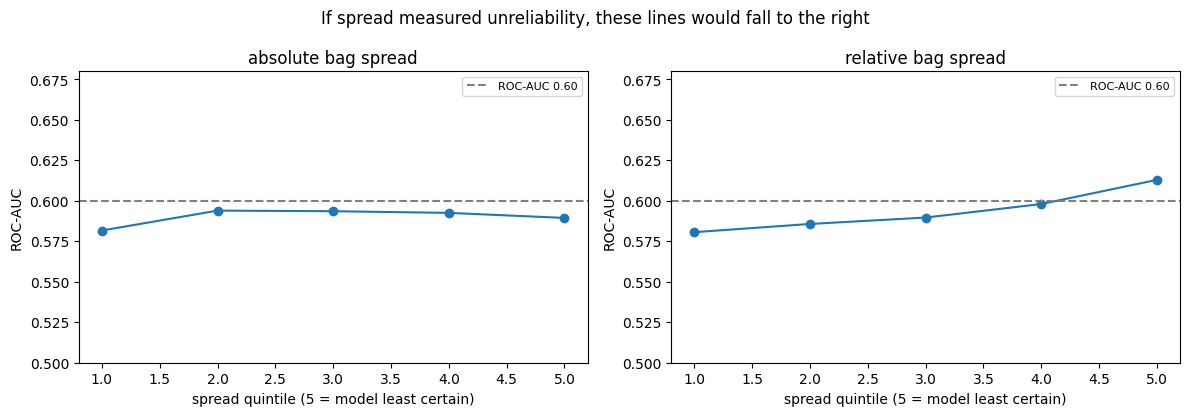

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, meas in zip(axes, ["absolute", "relative"]):
    s = v[v["measure"] == meas]
    ax.plot(s["quintile"], s["roc_auc"], "o-")
    ax.axhline(0.60, ls="--", c="grey", label="ROC-AUC 0.60")
    ax.set_title(f"{meas} bag spread")
    ax.set_xlabel("spread quintile (5 = model least certain)")
    ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.50, 0.68); ax.legend(fontsize=8)
fig.suptitle("If spread measured unreliability, these lines would fall to the right")
plt.tight_layout(); plt.show()

In [5]:
bag_w = (d["bag_hi"] - d["bag_lo"]).mean()
coh_w = (d["realised_hi"] - d["realised_lo"]).mean()
outside = ((d["p"] < d["bag_lo"]) | (d["p"] > d["bag_hi"])).mean()
print("how wide is each uncertainty source, in probability points?\n")
print(f"  bag band     (5-95%)  {bag_w:.4f}")
print(f"  cohort band  (95%)    {coh_w:.4f}   (median cohort {int(d['cohort_n'].median()):,} rows)")
print(f"\n  the served probability sits outside the bag band for {outside:.0%} of rows:")
print("  the logistic and the decomposition move it, so the band is not an interval on p")

how wide is each uncertainty source, in probability points?

  bag band     (5-95%)  0.0162
  cohort band  (95%)    0.0173   (median cohort 7,701 rows)

  the served probability sits outside the bag band for 55% of rows:
  the logistic and the decomposition move it, so the band is not an interval on p


Two things changed with the ensemble, and both show above. The **cohort interval is now
narrow**, because the pool behind it grew about fivefold (five leagues, six seasons), so it
is no longer much wider than the bag band. It is still the interval to read, because it is
an *empirical* check of the served number. And the **bag band is not an interval on `p`**:
`p` blends the bag with the logistic and the decomposition, so it often sits outside the
boosters' range.

## 2. Per-player confidence

`p` is the model's probability. `realised_lo`–`realised_hi` is the **interval to read**:
the match-clustered bootstrap range of the observed booking rate among historically
similar predictions. `breakeven` is `1 / price` — the probability the price demands.

**`clears_breakeven` is the column that matters**: the realised rate stays above what the
price needs even at the *bottom* of its interval.

In [6]:
COLS = ["player", "team", "grade", "p", "p_not_booked", "realised_lo", "realised_hi",
        "breakeven", "price", "edge", "clears_breakeven"]
d.head(20)[COLS]

,player,team,grade,p,p_not_booked,realised_lo,realised_hi,breakeven,price,edge,clears_breakeven
0,Antoine Semenyo,Manchester City,A - well supported,0.1938,0.8062,0.1813,0.2008,0.1333,7.5000,0.4532,True
1,Takehiro Tomiyasu,Crystal Palace,A - well supported,0.2314,0.7686,0.2132,0.2319,0.1667,6.0000,0.3881,True
2,Dominic Calvert-Lewin,Leeds United,A - well supported,0.1533,0.8467,0.1586,0.1694,0.1111,9.0000,0.3800,True
3,Daichi Kamada,Crystal Palace,A - well supported,0.2747,0.7253,0.2709,0.2959,0.2000,5.0000,0.3736,True
4,Elliot Anderson,Manchester City,A - well supported,0.2277,0.7723,0.2229,0.2399,0.1667,6.0000,0.3662,True
5,Quinten Timber,Crystal Palace,C - thin history,0.2462,0.7538,0.2432,0.2635,0.2000,5.0000,0.2310,True
6,Granit Xhaka,Sunderland,A - well supported,0.2695,0.7305,0.2664,0.2904,0.2222,4.5000,0.2126,True
7,Chris Richards,Crystal Palace,A - well supported,0.2003,0.7997,0.2013,0.2128,0.1667,6.0000,0.2019,True
8,James Hill,Bournemouth,A - well supported,0.1946,0.8054,0.1979,0.2091,0.1667,6.0000,0.1678,True
9,Tyrick Mitchell,Crystal Palace,A - well supported,0.1940,0.8060,0.1880,0.2039,0.1667,6.0000,0.1640,True


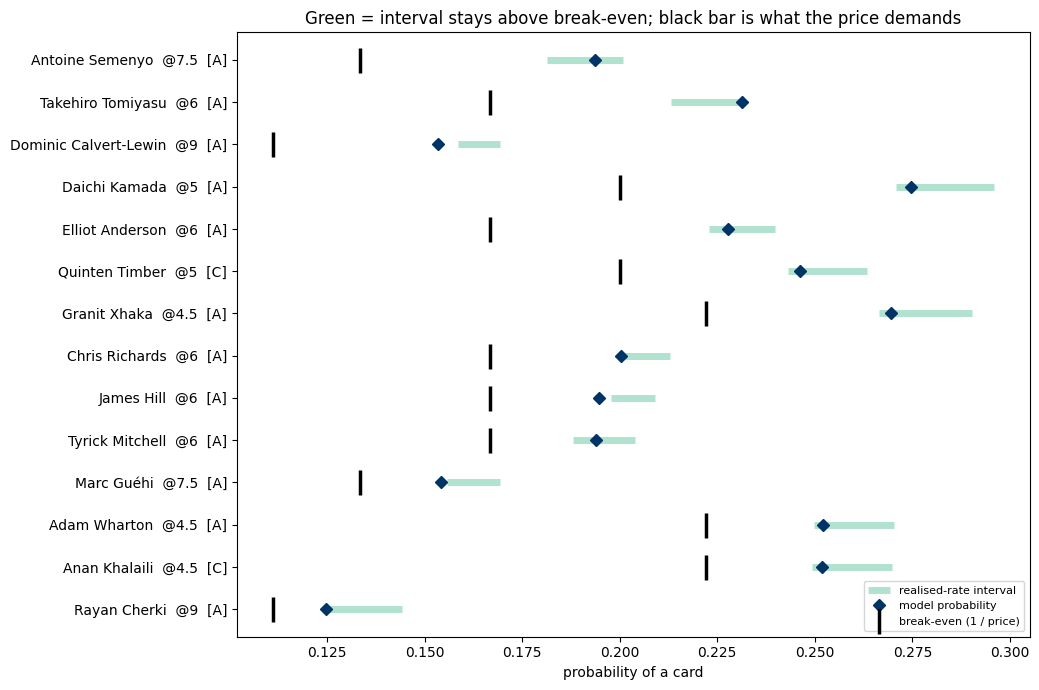

In [7]:
top = d.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(10.5, 7))
y = np.arange(len(top))
ax.hlines(y, top["realised_lo"], top["realised_hi"], lw=5, alpha=.35,
          color=["#2a7" if c else "#c33" for c in top["clears_breakeven"]],
          label="realised-rate interval")
ax.plot(top["p"], y, "D", ms=6, color="#036", label="model probability")
ax.plot(top["breakeven"], y, "|", ms=18, mew=2.5, color="k",
        label="break-even (1 / price)")
ax.set_yticks(y)
ax.set_yticklabels([f"{r.player}  @{r.price:g}  [{r.grade[0]}]"
                    for r in top.itertuples()])
ax.set_xlabel("probability of a card")
ax.set_title("Green = interval stays above break-even; black bar is what the price demands")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### The grades

Built only from moderators that replicated:

- **C — thin history**: ≤5 prior appearances or unknown position. ROC-AUC 0.536 vs 0.600.
  Discount regardless of how large the edge looks.
- **B — qualified**: the referee has no history in the dataset (features fall back to the
  league prior), or the historical cohort behind the row is thin (<400 rows).
- **A — well supported**: neither applies.

Bag spread is *not* an input, for the reason in §1b. It is shown in the table so you can
see how little the fit actually wobbles.

In [8]:
(d.groupby(["fixture", "grade"])
   .agg(n=("player", "size"), clears=("clears_breakeven", "sum"))
   .reset_index())

,fixture,grade,n,clears
0,Bournemouth v Liverpool,A - well supported,16,5
1,Bournemouth v Liverpool,C - thin history,4,0
2,Leeds United v Crystal Palace,A - well supported,16,7
3,Leeds United v Crystal Palace,C - thin history,4,2
4,Manchester City v Sunderland,A - well supported,18,5
5,Manchester City v Sunderland,C - thin history,2,0


In [9]:
d.groupby("grade").agg(n=("player", "size"),
                       mean_p=("p", "mean"),
                       mean_cohort_width=("realised_hi", "mean"),
                       clears=("clears_breakeven", "sum"))

,n,mean_p,mean_cohort_width,clears
grade,,,,
A - well supported,50,0.1902,0.2033,17
C - thin history,10,0.1951,0.2064,2


## 3. How to read a row

Take the best-supported row on the slate and walk through it.

1. **The model says `p`.** That is a rate, not a prediction of this match.
2. **`p_not_booked` is what usually happens.** At these levels every single pick is odds-
   against. A run of losses is the expected experience, not a malfunction.
3. **The interval is `realised_lo`–`realised_hi`**, not the bag band. §1b showed the bag
   band covers only the boosters' wobble, and that `p` need not even sit inside it.
4. **Compare the interval's floor to `breakeven`.** If the floor clears it, the row
   survives the uncertainty that can actually be measured.
5. **Then read the grade**, which captures the uncertainty that *can't* be put in an
   interval — thin history, an unknown referee, a thin cohort.

What none of this can tell you: whether the market knows something the model doesn't.
There are no historical player-card prices, so that is untestable here. It is the largest
remaining risk and it is not in any interval on this page.

In [10]:
r = d[d["grade"].str.startswith("A")].iloc[0]
print(f"{r['player']} ({r['team']}) @ {r['price']:g}\n")
print(f"  model probability      {r['p']:.4f}")
print(f"  NOT booked             {r['p_not_booked']:.4f}   <- the usual outcome")
print(f"  realised interval      {r['realised_lo']:.4f} - {r['realised_hi']:.4f}"
      f"   (n={int(r['cohort_n'])} similar past rows)")
print(f"  bag band               {r['bag_lo']:.4f} - {r['bag_hi']:.4f}"
      f"   (fit wobble only - not the interval to read)")
print(f"  break-even at {r['price']:g}      {r['breakeven']:.4f}")
print(f"  clears break-even?     {bool(r['clears_breakeven'])}")
print(f"  grade                  {r['grade']}")

Antoine Semenyo (Manchester City) @ 7.5

  model probability      0.1938
  NOT booked             0.8062   <- the usual outcome
  realised interval      0.1813 - 0.2008   (n=6069 similar past rows)
  bag band               0.1798 - 0.1998   (fit wobble only - not the interval to read)
  break-even at 7.5      0.1333
  clears break-even?     True
  grade                  A - well supported


In [11]:
# scratch
d.columns.tolist()

['fixture',
 'league',
 'player',
 'team',
 'pos_group',
 'thin',
 'ref_known',
 'apps',
 'p',
 'bag_sd',
 'bag_lo',
 'bag_hi',
 'rel_spread',
 'cohort_n',
 'realised',
 'realised_lo',
 'realised_hi',
 'price',
 'breakeven',
 'edge',
 'p_not_booked',
 'grade',
 'clears_breakeven']